In [3]:
import os

In [4]:
%pwd

'c:\\Users\\sagal\\Desktop\\Let us build\\deforestation_detection\\research'

In [5]:
os.chdir('../')

In [6]:
%pwd

'c:\\Users\\sagal\\Desktop\\Let us build\\deforestation_detection'

In [7]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import random
import numpy as np

# Verify Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# Load cached dataset arrays from the root-level models directory
data_save_path = os.path.join("models", "dataset_arrays.pt")

if os.path.exists(data_save_path):
    print(f"[INFO] Loading cached dataset arrays from '{data_save_path}'...")
    data = torch.load(data_save_path)
    X_full = data['X_full']
    y_full = data['y_full']
else:
    raise FileNotFoundError(f"Dataset cache not found at {data_save_path}. Please check your path!")

print(f"Loaded dataset shape - Images: {X_full.shape}, Masks: {y_full.shape}")

# 80/20 Train/Test Split
torch.manual_seed(42)
num_total = X_full.shape[0]
indices = torch.randperm(num_total)
split_idx = int(0.8 * num_total)

X_tr, y_tr = X_full[indices[:split_idx]], y_full[indices[:split_idx]]
X_te, y_te = X_full[indices[split_idx:]], y_full[indices[split_idx:]]
print(f"Training samples: {X_tr.shape[0]}, Test samples: {X_te.shape[0]}")

Using device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
[INFO] Loading cached dataset arrays from 'models\dataset_arrays.pt'...
Loaded dataset shape - Images: torch.Size([144, 4, 256, 256]), Masks: torch.Size([144, 1, 256, 256])
Training samples: 115, Test samples: 29


In [10]:
import sys
!{sys.executable} -m pip install segmentation-models-pytorch

  Using cached safetensors-0.8.0-cp310-abi3-win_amd64.whl.metadata (4.2 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached pyyaml-6.0.3-cp310-cp310-win_amd64.whl.metadata (2.4 kB)
  Using cached anyio-4.15.1-py3-none-any.whl.metadata (4.7 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
   ---------------------------------------- 0.0/839.9 kB ? eta -:--:--
   ---------------------------------------- 839.9/839.9 kB 12.3 MB/s  0:00:00
   ---------------------------------------- 0.0/3.8 MB ? eta -:--:--
   ---------------------------------------- 3.8/3.8 MB 37.9 MB/s  0:00:00
Using cached anyio-4.15.1-py3-none-any.whl (132 kB)
Using cached h11-0.16.0-py3-none-any.whl (37 kB)
Using cached pyyaml-6.0.3-cp310-cp310-win_amd64.whl (158 kB)
Using cached safetensors-0.8.0-cp310-abi3-win_amd64.whl (355 kB)
   ---------------------------------------- 0.0/2.7 MB ? eta -:--:--
   ---------------------------------------- 2.7/2.7 MB 38.8 MB/s  0:00:00
Using

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [10]:
# Install segmentation-models-pytorch if not already installed in your environment:
# !pip install segmentation-models-pytorch

import segmentation_models_pytorch as smp

# Initialize U-Net with a pre-trained ResNet34 encoder
# in_channels=4 handles our RGBN stack, classes=1 for binary deforestation mask
model = smp.Unet(
    encoder_name="resnet34",      # Robust pre-trained backbone
    encoder_weights="imagenet",   # Transfer learning initialization
    in_channels=4,                # B4, B3, B2, B8
    classes=1,                    # Binary output (deforestation vs background)
).to(device)

print("Pre-trained U-Net (ResNet34 backbone) successfully initialized!")

Pre-trained U-Net (ResNet34 backbone) successfully initialized!


In [12]:
import torch.nn.functional as F

# 1. Define a Combined Loss (Focal Loss + Dice Loss) to handle sparse deforestation pixels
class FocalDiceLoss(nn.Module):
    def __init__(self, alpha=0.8, gamma=2.0, smooth=1.0):
        super(FocalDiceLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.smooth = smooth

    def forward(self, inputs, targets):
        # Flatten inputs and targets
        inputs = torch.sigmoid(inputs)
        inputs_flat = inputs.view(-1)
        targets_flat = targets.view(-1)
        
        # Focal Loss component
        BCE = F.binary_cross_entropy(inputs_flat, targets_flat, reduction='none')
        pt = torch.exp(-BCE)
        focal_loss = self.alpha * (1 - pt)**self.gamma * BCE
        focal_loss = focal_loss.mean()
        
        # Dice Loss component
        intersection = (inputs_flat * targets_flat).sum()
        dice_loss = 1 - (2. * intersection + self.smooth) / (inputs_flat.sum() + targets_flat.sum() + self.smooth)
        
        return focal_loss + dice_loss

criterion = FocalDiceLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-3)

# 2. Quick Forward Pass Sanity Check
model.eval()
with torch.no_grad():
    sample_batch = X_tr[:4].float().to(device)
    dummy_out = model(sample_batch)
    print(f"Sanity Check - Input Batch Shape: {sample_batch.shape}")
    print(f"Sanity Check - Model Output Shape: {dummy_out.shape}")
    print("Model forward pass successful!")

Sanity Check - Input Batch Shape: torch.Size([4, 4, 256, 256])
Sanity Check - Model Output Shape: torch.Size([4, 1, 256, 256])
Model forward pass successful!


In [13]:
from torch.utils.data import DataLoader
# Make sure os is imported
import os

# 1. Create DataLoaders
batch_size = 8
train_dataset = TensorDataset(X_tr.float(), y_tr.float())
test_dataset = TensorDataset(X_te.float(), y_te.float())

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# 2. Training Configuration
epochs = 15
best_val_loss = float('inf')
os.makedirs("models", exist_ok=True)
save_path = os.path.join("models", "best_unet_transfer_learning.pth")

print(f"Starting training for {epochs} epochs using device: {device}\n" + "-"*50)

for epoch in range(epochs):
    # --- TRAINING ---
    model.train()
    train_loss = 0.0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)
        
        # Ensure mask has channel dimension [B, 1, H, W]
        if masks.ndim == 3:
            masks = masks.unsqueeze(1)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * images.size(0)
        
    epoch_train_loss = train_loss / len(train_loader.dataset)
    
    # --- VALIDATION ---
    model.eval()
    val_loss = 0.0
    intersection_sum = 0.0
    union_sum = 0.0
    
    with torch.no_grad():
        for images, masks in test_loader:
            images, masks = images.to(device), masks.to(device)
            if masks.ndim == 3:
                masks = masks.unsqueeze(1)
                
            outputs = model(images)
            loss = criterion(outputs, masks)
            val_loss += loss.item() * images.size(0)
            
            # Calculate Intersection over Union (IoU) metrics
            preds = (torch.sigmoid(outputs) > 0.5).float()
            intersection = (preds * masks).sum()
            union = preds.sum() + masks.sum() - intersection
            
            intersection_sum += intersection.item()
            union_sum += union.item()
            
    epoch_val_loss = val_loss / len(test_loader.dataset)
    val_iou = (intersection_sum + 1e-6) / (union_sum + 1e-6)
    
    # Save Best Model Checkpoint
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), save_path)
        saved_tag = " [SAVED BEST]"
    else:
        saved_tag = ""
        
    print(f"Epoch [{epoch+1:02d}/{epochs:02d}] | "
          f"Train Loss: {epoch_train_loss:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f} | "
          f"Val IoU: {val_iou:.4f}{saved_tag}")

print("-" * 50 + f"\nTraining Complete! Best model saved to '{save_path}'")

Starting training for 15 epochs using device: cuda
--------------------------------------------------
Epoch [01/15] | Train Loss: 1.3589 | Val Loss: 1.2813 | Val IoU: 0.0034 [SAVED BEST]
Epoch [02/15] | Train Loss: 1.1854 | Val Loss: 1.1796 | Val IoU: 0.0036 [SAVED BEST]
Epoch [03/15] | Train Loss: 1.1253 | Val Loss: 1.1270 | Val IoU: 0.0039 [SAVED BEST]
Epoch [04/15] | Train Loss: 1.1002 | Val Loss: 1.0972 | Val IoU: 0.0041 [SAVED BEST]
Epoch [05/15] | Train Loss: 1.0818 | Val Loss: 1.0764 | Val IoU: 0.0044 [SAVED BEST]
Epoch [06/15] | Train Loss: 1.0696 | Val Loss: 1.0686 | Val IoU: 0.0033 [SAVED BEST]
Epoch [07/15] | Train Loss: 1.0546 | Val Loss: 1.0494 | Val IoU: 0.0049 [SAVED BEST]
Epoch [08/15] | Train Loss: 1.0412 | Val Loss: 1.0372 | Val IoU: 0.0019 [SAVED BEST]
Epoch [09/15] | Train Loss: 1.0323 | Val Loss: 1.0274 | Val IoU: 0.0009 [SAVED BEST]
Epoch [10/15] | Train Loss: 1.0253 | Val Loss: 1.0221 | Val IoU: 0.0444 [SAVED BEST]
Epoch [11/15] | Train Loss: 1.0198 | Val Loss: 1

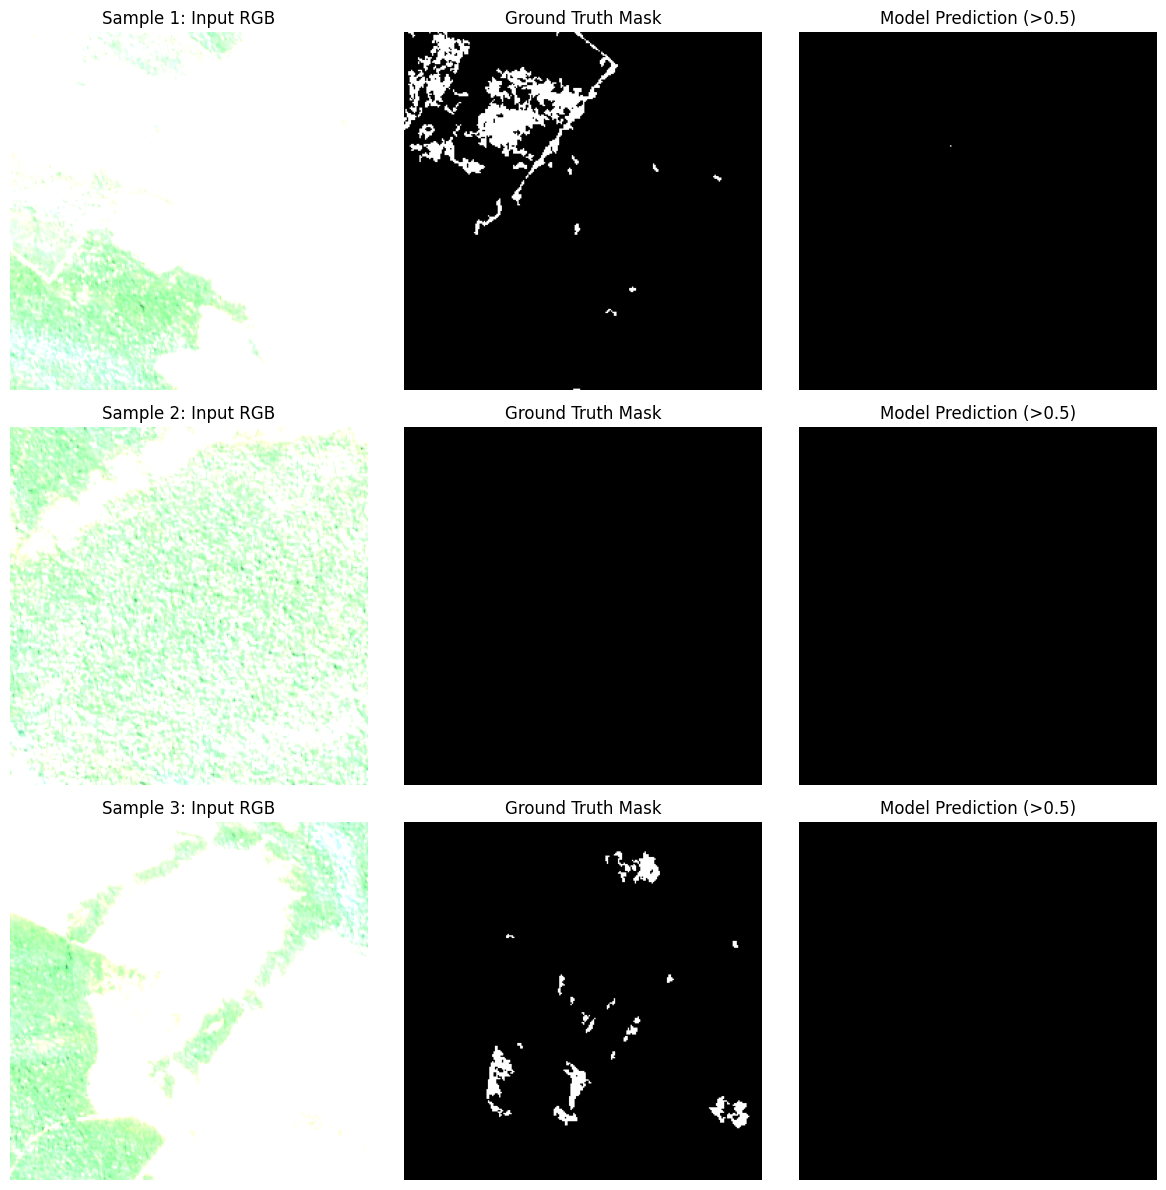

In [17]:
import matplotlib.pyplot as plt
import numpy as np

model.load_state_dict(torch.load(os.path.join("models", "best_unet_transfer_learning.pth")))
model.eval()

images_vis = X_te[:3].float().to(device)
masks_vis = y_te[:3].float().to(device)

with torch.no_grad():
    outputs = model(images_vis)
    preds = torch.sigmoid(outputs)
    pred_masks = (preds > 0.5).float() # Raised threshold to 0.5 to reduce false positives

images_cpu = images_vis.cpu().numpy()
masks_cpu = masks_vis.cpu().numpy()
preds_cpu = pred_masks.cpu().numpy()

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for i in range(3):
    # Transpose to (H, W, C)
    rgb_img = np.transpose(images_cpu[i, :3, :, :], (1, 2, 0))
    
    # Dynamically normalize RGB for display if values are in 0-255 range
    if rgb_img.max() > 1.0:
        rgb_img = rgb_img / 255.0
    rgb_img = np.clip(rgb_img, 0, 1)
    
    axes[i, 0].imshow(rgb_img)
    axes[i, 0].set_title(f"Sample {i+1}: Input RGB")
    axes[i, 0].axis('off')
    
    axes[i, 1].imshow(np.squeeze(masks_cpu[i]), cmap='gray')
    axes[i, 1].set_title("Ground Truth Mask")
    axes[i, 1].axis('off')
    
    axes[i, 2].imshow(np.squeeze(preds_cpu[i]), cmap='gray')
    axes[i, 2].set_title("Model Prediction (>0.5)")
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()

In [18]:
model.eval()
with torch.no_grad():
    sample_out = model(images_vis)
    sample_probs = torch.sigmoid(sample_out)
    print(f"Min probability output: {sample_probs.min().item():.6f}")
    print(f"Max probability output: {sample_probs.max().item():.6f}")
    print(f"Mean probability output: {sample_probs.mean().item():.6f}")

Min probability output: 0.181214
Max probability output: 0.503572
Mean probability output: 0.272369


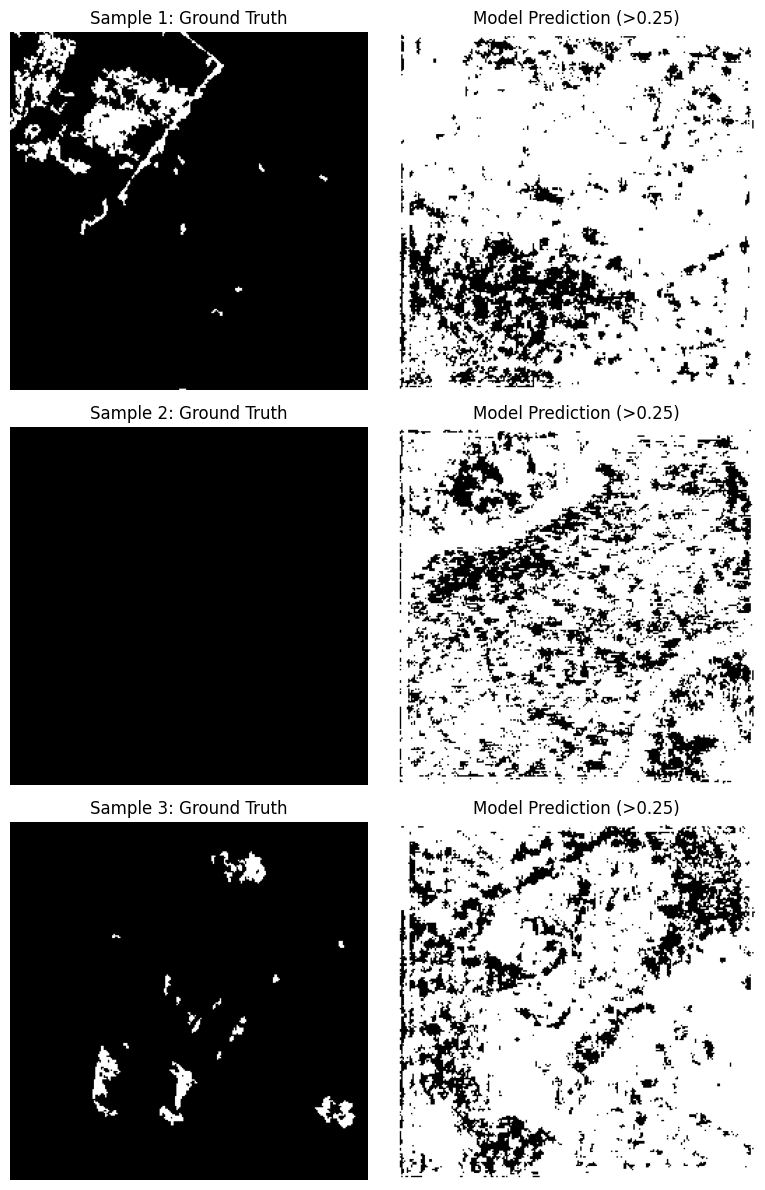

In [19]:
with torch.no_grad():
    outputs = model(images_vis)
    preds = torch.sigmoid(outputs)
    pred_masks = (preds > 0.25).float() # Lowered threshold to catch the 0.27 mean

preds_cpu = pred_masks.cpu().numpy()

fig, axes = plt.subplots(3, 2, figsize=(8, 12))
for i in range(3):
    axes[i, 0].imshow(np.squeeze(masks_cpu[i]), cmap='gray')
    axes[i, 0].set_title(f"Sample {i+1}: Ground Truth")
    axes[i, 0].axis('off')
    
    axes[i, 1].imshow(np.squeeze(preds_cpu[i]), cmap='gray')
    axes[i, 1].set_title("Model Prediction (>0.25)")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

Trial-10

In [20]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torch.nn.functional as F
import os

# 1. Define an improved loss: Weighted BCE + Smooth Dice Loss
class WeightedBCEDiceLoss(nn.Module):
    def __init__(self, pos_weight=5.0, smooth=1.0):
        super(WeightedBCEDiceLoss, self).__init__()
        self.pos_weight = torch.tensor([pos_weight]).to(device)
        self.smooth = smooth

    def forward(self, inputs, targets):
        # Flatten
        inputs_sig = torch.sigmoid(inputs)
        inputs_flat = inputs_sig.view(-1)
        targets_flat = targets.view(-1)
        
        # Weighted BCE Loss to penalize background false positives
        bce_loss = F.binary_cross_entropy_with_logits(
            inputs.view(-1), targets_flat, pos_weight=self.pos_weight
        )
        
        # Dice Loss component
        intersection = (inputs_flat * targets_flat).sum()
        dice_loss = 1 - (2. * intersection + self.smooth) / (inputs_flat.sum() + targets_flat.sum() + self.smooth)
        
        return bce_loss + dice_loss

# Re-initialize criterion and optimizer with safer learning rate
criterion_trial10 = WeightedBCEDiceLoss(pos_weight=5.0)
optimizer_trial10 = optim.AdamW(model.parameters(), lr=5e-5, weight_decay=1e-3)

# 2. Training Configuration
epochs_trial10 = 15
best_val_loss_10 = float('inf')
save_path_10 = os.path.join("models", "best_unet_trial_10.pth")

print(f"Starting Trial 10 Training for {epochs_trial10} epochs (Weighted Loss + Lower LR)\n" + "-"*60)

for epoch in range(epochs_trial10):
    # --- TRAINING ---
    model.train()
    train_loss = 0.0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)
        if masks.ndim == 3:
            masks = masks.unsqueeze(1)

        optimizer_trial10.zero_grad()
        outputs = model(images)
        loss = criterion_trial10(outputs, masks)
        loss.backward()
        optimizer_trial10.step()
        
        train_loss += loss.item() * images.size(0)
        
    epoch_train_loss = train_loss / len(train_loader.dataset)
    
    # --- VALIDATION ---
    model.eval()
    val_loss = 0.0
    intersection_sum = 0.0
    union_sum = 0.0
    
    with torch.no_grad():
        for images, masks in test_loader:
            images, masks = images.to(device), masks.to(device)
            if masks.ndim == 3:
                masks = masks.unsqueeze(1)
                
            outputs = model(images)
            loss = criterion_trial10(outputs, masks)
            val_loss += loss.item() * images.size(0)
            
            # Metrics with standard 0.5 threshold
            preds = (torch.sigmoid(outputs) > 0.5).float()
            intersection = (preds * masks).sum()
            union = preds.sum() + masks.sum() - intersection
            
            intersection_sum += intersection.item()
            union_sum += union.item()
            
    epoch_val_loss = val_loss / len(test_loader.dataset)
    val_iou = (intersection_sum + 1e-6) / (union_sum + 1e-6)
    
    # Save Best Checkpoint for Trial 10
    if epoch_val_loss < best_val_loss_10:
        best_val_loss_10 = epoch_val_loss
        torch.save(model.state_dict(), save_path_10)
        saved_tag = " [SAVED TRIAL 10 BEST]"
    else:
        saved_tag = ""
        
    print(f"Epoch [{epoch+1:02d}/{epochs_trial10:02d}] | "
          f"Train Loss: {epoch_train_loss:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f} | "
          f"Val IoU: {val_iou:.4f}{saved_tag}")

print("-" * 60 + f"\nTrial 10 Complete! Saved to '{save_path_10}'")

Starting Trial 10 Training for 15 epochs (Weighted Loss + Lower LR)
------------------------------------------------------------
Epoch [01/15] | Train Loss: 1.3044 | Val Loss: 1.3092 | Val IoU: 0.0069 [SAVED TRIAL 10 BEST]
Epoch [02/15] | Train Loss: 1.2894 | Val Loss: 1.2997 | Val IoU: 0.0054 [SAVED TRIAL 10 BEST]
Epoch [03/15] | Train Loss: 1.2761 | Val Loss: 1.2913 | Val IoU: 0.0000 [SAVED TRIAL 10 BEST]
Epoch [04/15] | Train Loss: 1.2652 | Val Loss: 1.2824 | Val IoU: 0.0116 [SAVED TRIAL 10 BEST]
Epoch [05/15] | Train Loss: 1.2553 | Val Loss: 1.2738 | Val IoU: 0.0108 [SAVED TRIAL 10 BEST]
Epoch [06/15] | Train Loss: 1.2491 | Val Loss: 1.2718 | Val IoU: 0.0113 [SAVED TRIAL 10 BEST]
Epoch [07/15] | Train Loss: 1.2409 | Val Loss: 1.2631 | Val IoU: 0.0083 [SAVED TRIAL 10 BEST]
Epoch [08/15] | Train Loss: 1.2345 | Val Loss: 1.2577 | Val IoU: 0.0007 [SAVED TRIAL 10 BEST]
Epoch [09/15] | Train Loss: 1.2243 | Val Loss: 1.2464 | Val IoU: 0.0499 [SAVED TRIAL 10 BEST]
Epoch [10/15] | Train Los

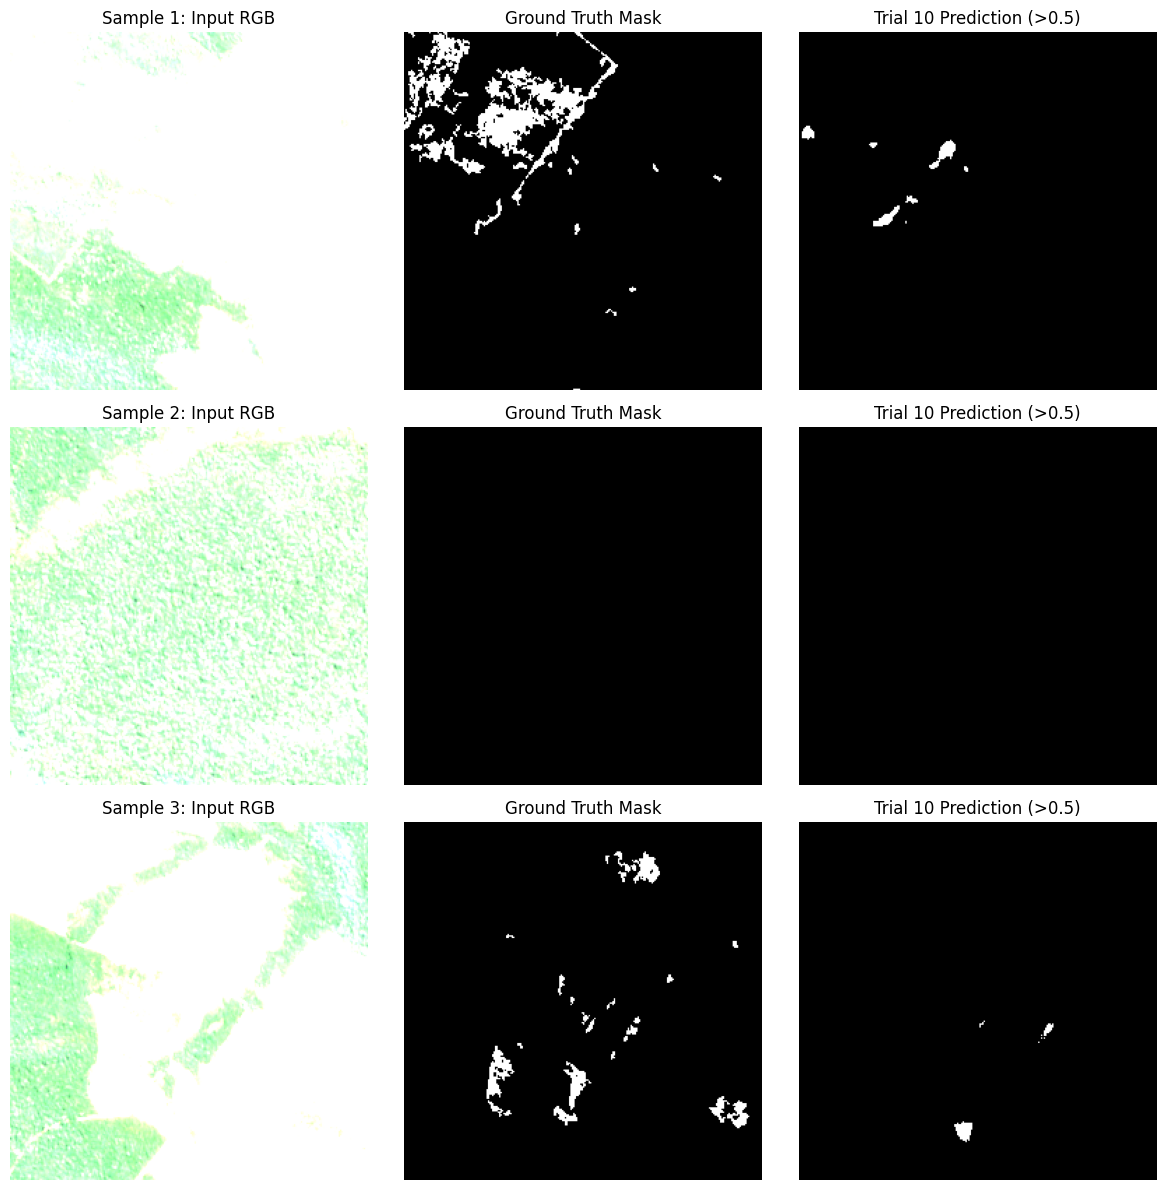

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import os
import torch

# Load Trial 10 weights
trial_10_path = os.path.join("models", "best_unet_trial_10.pth")
model.load_state_dict(torch.load(trial_10_path))
model.eval()

images_vis = X_te[:3].float().to(device)
masks_vis = y_te[:3].float().to(device)

with torch.no_grad():
    outputs = model(images_vis)
    preds = torch.sigmoid(outputs)
    pred_masks = (preds > 0.5).float() # Standard 0.5 threshold with Trial 10

images_cpu = images_vis.cpu().numpy()
masks_cpu = masks_vis.cpu().numpy()
preds_cpu = pred_masks.cpu().numpy()

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for i in range(3):
    # RGB composite from 4-channel input
    rgb_img = np.transpose(images_cpu[i, :3, :, :], (1, 2, 0))
    if rgb_img.max() > 1.0:
        rgb_img = rgb_img / 255.0
    rgb_img = np.clip(rgb_img, 0, 1)
    
    axes[i, 0].imshow(rgb_img)
    axes[i, 0].set_title(f"Sample {i+1}: Input RGB")
    axes[i, 0].axis('off')
    
    axes[i, 1].imshow(np.squeeze(masks_cpu[i]), cmap='gray')
    axes[i, 1].set_title("Ground Truth Mask")
    axes[i, 1].axis('off')
    
    axes[i, 2].imshow(np.squeeze(preds_cpu[i]), cmap='gray')
    axes[i, 2].set_title("Trial 10 Prediction (>0.5)")
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()

Trial -11 => extended training of trial 10

In [22]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
import os

# 1. Load the best weights from Trial 10 as our baseline
trial_10_path = os.path.join("models", "best_unet_trial_10.pth")
model.load_state_dict(torch.load(trial_10_path))

# 2. Re-initialize Weighted Loss and set a lower Learning Rate (1e-5)
criterion_trial11 = WeightedBCEDiceLoss(pos_weight=5.0)
optimizer_trial11 = optim.AdamW(model.parameters(), lr=1e-5, weight_decay=1e-3)

epochs_trial11 = 15
scheduler = CosineAnnealingLR(optimizer_trial11, T_max=epochs_trial11, eta_min=1e-6)

best_val_loss_11 = best_val_loss_10
save_path_11 = os.path.join("models", "best_unet_trial_11.pth")

print(f"Starting Extended Training (Trial 11) for {epochs_trial11} epochs (LR: 1e-5 -> 1e-6)\n" + "-"*65)

for epoch in range(epochs_trial11):
    # --- TRAINING ---
    model.train()
    train_loss = 0.0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)
        if masks.ndim == 3:
            masks = masks.unsqueeze(1)

        optimizer_trial11.zero_grad()
        outputs = model(images)
        loss = criterion_trial11(outputs, masks)
        loss.backward()
        optimizer_trial11.step()
        
        train_loss += loss.item() * images.size(0)
        
    epoch_train_loss = train_loss / len(train_loader.dataset)
    scheduler.step()
    
    # --- VALIDATION ---
    model.eval()
    val_loss = 0.0
    intersection_sum = 0.0
    union_sum = 0.0
    
    with torch.no_grad():
        for images, masks in test_loader:
            images, masks = images.to(device), masks.to(device)
            if masks.ndim == 3:
                masks = masks.unsqueeze(1)
                
            outputs = model(images)
            loss = criterion_trial11(outputs, masks)
            val_loss += loss.item() * images.size(0)
            
            # Metric calculation with standard 0.5 threshold
            preds = (torch.sigmoid(outputs) > 0.5).float()
            intersection = (preds * masks).sum()
            union = preds.sum() + masks.sum() - intersection
            
            intersection_sum += intersection.item()
            union_sum += union.item()
            
    epoch_val_loss = val_loss / len(test_loader.dataset)
    val_iou = (intersection_sum + 1e-6) / (union_sum + 1e-6)
    
    # Save Best Checkpoint for Trial 11
    if epoch_val_loss < best_val_loss_11:
        best_val_loss_11 = epoch_val_loss
        torch.save(model.state_dict(), save_path_11)
        saved_tag = " [SAVED TRIAL 11 BEST]"
    else:
        saved_tag = ""
        
    current_lr = optimizer_trial11.param_groups[0]['lr']
    print(f"Epoch [{epoch+1:02d}/{epochs_trial11:02d}] | LR: {current_lr:.2e} | "
          f"Train Loss: {epoch_train_loss:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f} | "
          f"Val IoU: {val_iou:.4f}{saved_tag}")

print("-" * 65 + f"\nTrial 11 Complete! Best extended model saved to '{save_path_11}'")

Starting Extended Training (Trial 11) for 15 epochs (LR: 1e-5 -> 1e-6)
-----------------------------------------------------------------
Epoch [01/15] | LR: 9.90e-06 | Train Loss: 1.1771 | Val Loss: 1.2166 | Val IoU: 0.0090 [SAVED TRIAL 11 BEST]
Epoch [02/15] | LR: 9.61e-06 | Train Loss: 1.1754 | Val Loss: 1.2175 | Val IoU: 0.0171
Epoch [03/15] | LR: 9.14e-06 | Train Loss: 1.1714 | Val Loss: 1.2155 | Val IoU: 0.0086 [SAVED TRIAL 11 BEST]
Epoch [04/15] | LR: 8.51e-06 | Train Loss: 1.1736 | Val Loss: 1.2151 | Val IoU: 0.0062 [SAVED TRIAL 11 BEST]
Epoch [05/15] | LR: 7.75e-06 | Train Loss: 1.1707 | Val Loss: 1.2134 | Val IoU: 0.0154 [SAVED TRIAL 11 BEST]
Epoch [06/15] | LR: 6.89e-06 | Train Loss: 1.1682 | Val Loss: 1.2122 | Val IoU: 0.0144 [SAVED TRIAL 11 BEST]
Epoch [07/15] | LR: 5.97e-06 | Train Loss: 1.1675 | Val Loss: 1.2118 | Val IoU: 0.0083 [SAVED TRIAL 11 BEST]
Epoch [08/15] | LR: 5.03e-06 | Train Loss: 1.1658 | Val Loss: 1.2113 | Val IoU: 0.0099 [SAVED TRIAL 11 BEST]
Epoch [09/15]

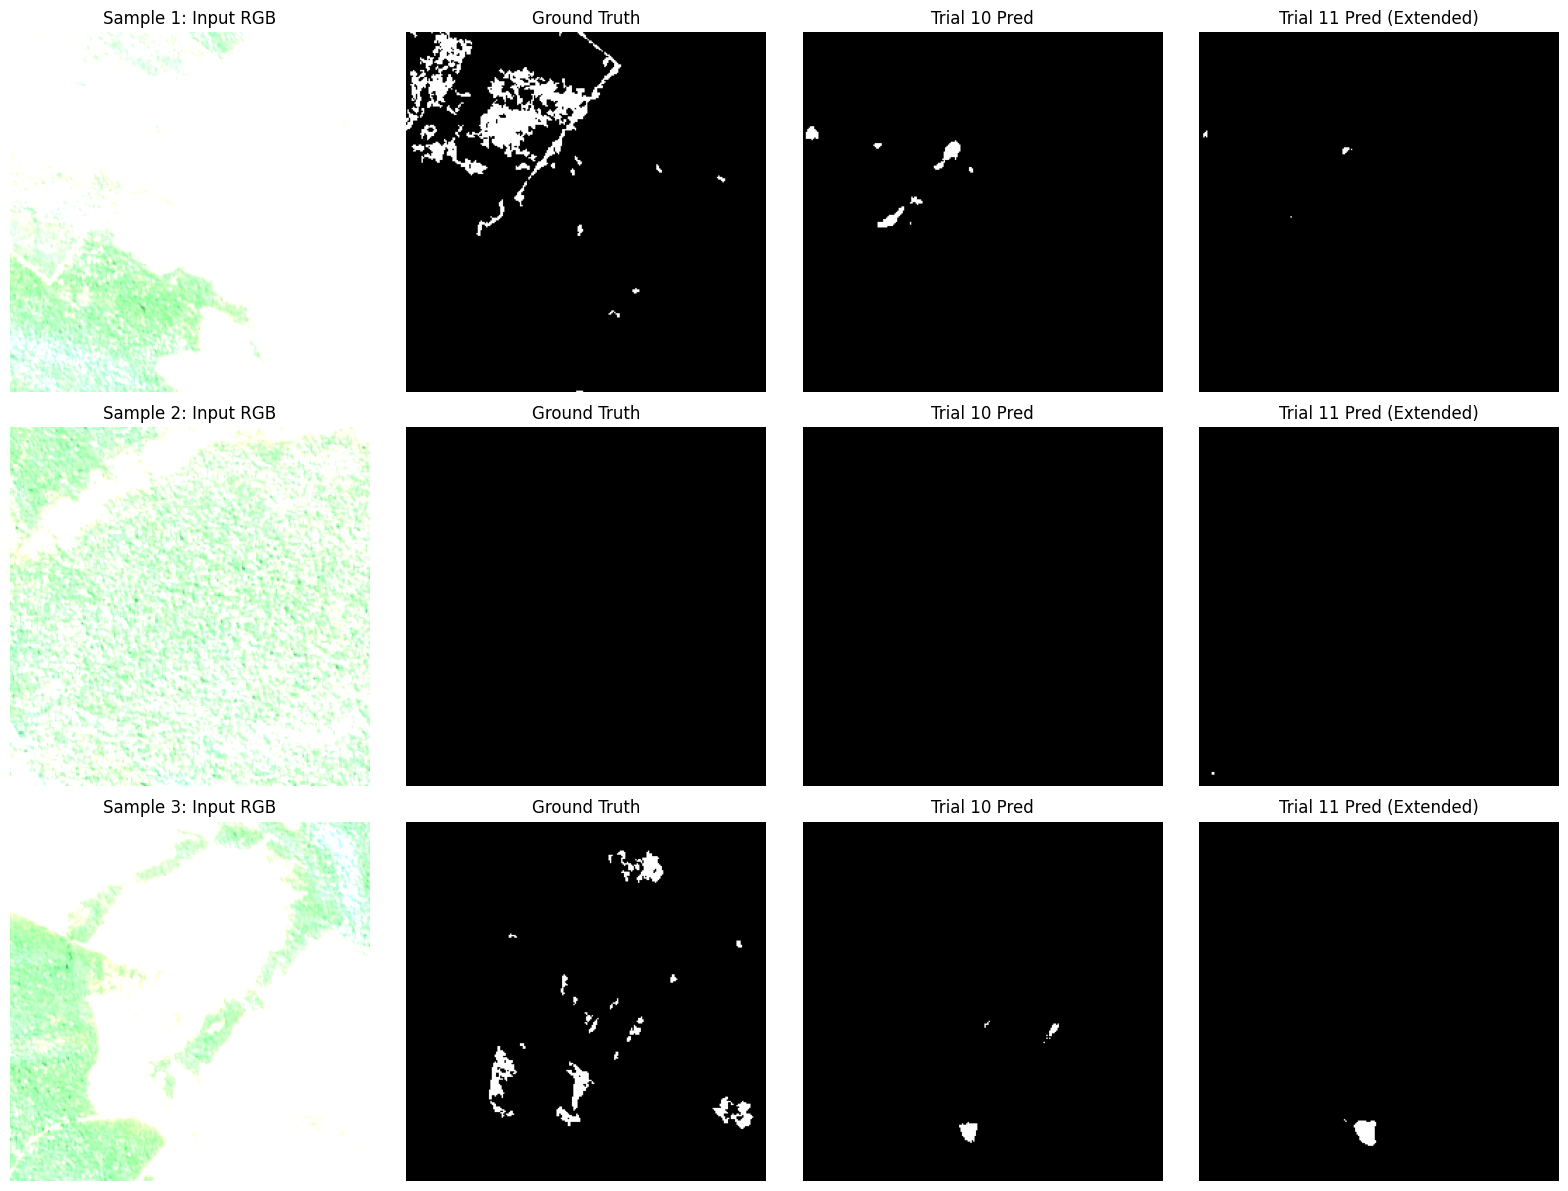

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import os
import torch
import segmentation_models_pytorch as smp

# 1. Load both models using the correct 'smp' alias
model_10 = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=4,
    classes=1
).to(device)

model_11 = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=4,
    classes=1
).to(device)

model_10.load_state_dict(torch.load(os.path.join("models", "best_unet_trial_10.pth")))
model_11.load_state_dict(torch.load(os.path.join("models", "best_unet_trial_11.pth")))

model_10.eval()
model_11.eval()

# 2. Grab test samples
images_vis = X_te[:3].float().to(device)
masks_vis = y_te[:3].float().to(device)

with torch.no_grad():
    preds_10 = (torch.sigmoid(model_10(images_vis)) > 0.5).float()
    preds_11 = (torch.sigmoid(model_11(images_vis)) > 0.5).float()

images_cpu = images_vis.cpu().numpy()
masks_cpu = masks_vis.cpu().numpy()
p10_cpu = preds_10.cpu().numpy()
p11_cpu = preds_11.cpu().numpy()

# 3. Plot comparison
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for i in range(3):
    rgb_img = np.transpose(images_cpu[i, :3, :, :], (1, 2, 0))
    if rgb_img.max() > 1.0:
        rgb_img = rgb_img / 255.0
    rgb_img = np.clip(rgb_img, 0, 1)
    
    # Input RGB
    axes[i, 0].imshow(rgb_img)
    axes[i, 0].set_title(f"Sample {i+1}: Input RGB")
    axes[i, 0].axis('off')
    
    # Ground Truth
    axes[i, 1].imshow(np.squeeze(masks_cpu[i]), cmap='gray')
    axes[i, 1].set_title("Ground Truth")
    axes[i, 1].axis('off')
    
    # Trial 10 Prediction
    axes[i, 2].imshow(np.squeeze(p10_cpu[i]), cmap='gray')
    axes[i, 2].set_title("Trial 10 Pred")
    axes[i, 2].axis('off')
    
    # Trial 11 Prediction
    axes[i, 3].imshow(np.squeeze(p11_cpu[i]), cmap='gray')
    axes[i, 3].set_title("Trial 11 Pred (Extended)")
    axes[i, 3].axis('off')

plt.tight_layout()
plt.show()

Trial -12

In [17]:
import sys
!{sys.executable} -m pip install scikit-learn segmentation-models-pytorch

  Using cached scikit_learn-1.7.2-cp310-cp310-win_amd64.whl.metadata (11 kB)
  Using cached scipy-1.15.3-cp310-cp310-win_amd64.whl.metadata (60 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.7.2-cp310-cp310-win_amd64.whl (8.9 MB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached scipy-1.15.3-cp310-cp310-win_amd64.whl (41.3 MB)

   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- --------------------------

In [18]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
import segmentation_models_pytorch as smp
import os
import numpy as np

# 1. Setup Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 2. Load full dataset arrays from the models directory
data_path = os.path.join("models", "dataset_arrays.pt")
if not os.path.exists(data_path):
    data_path = "dataset_arrays.pt"

dataset_dict = torch.load(data_path)
X_full = dataset_dict["X_full"]
y_full = dataset_dict["y_full"]
print(f"Loaded X_full shape: {X_full.shape}, y_full shape: {y_full.shape}")

# 3. Recreate the exact Train/Test Split (adjust random_state if your notebook used a specific seed)
X_tr, X_te, y_tr, y_te = train_test_split(X_full, y_full, test_size=0.2, random_state=42)
print(f"Train samples: {X_tr.shape[0]}, Test samples: {X_te.shape[0]}")

# 4. Rebuild DataLoaders
train_dataset = TensorDataset(X_tr, y_tr)
test_dataset = TensorDataset(X_te, y_te)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

# 5. Initialize Model & Load Trial 10 Weights
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=4,
    classes=1
).to(device)

trial_10_path = os.path.join("models", "best_unet_trial_10.pth")
model.load_state_dict(torch.load(trial_10_path))
print("Loaded Trial 10 checkpoint successfully as the base for Trial 12.")

# 6. Define Refined Loss & Optimizer for Trial 12
class RefinedWeightedBCEDiceLoss(nn.Module):
    def __init__(self, pos_weight=3.0, smooth=1.0):
        super().__init__()
        self.pos_weight = torch.tensor([pos_weight]).to(device)
        self.smooth = smooth

    def forward(self, inputs, targets):
        inputs_sig = torch.sigmoid(inputs)
        inputs_flat = inputs_sig.view(-1)
        targets_flat = targets.view(-1)
        
        bce_loss = F.binary_cross_entropy_with_logits(
            inputs.view(-1), targets_flat, pos_weight=self.pos_weight
        )
        intersection = (inputs_flat * targets_flat).sum()
        dice_loss = 1 - (2. * intersection + self.smooth) / (inputs_flat.sum() + targets_flat.sum() + self.smooth)
        
        return bce_loss + dice_loss

criterion_trial12 = RefinedWeightedBCEDiceLoss(pos_weight=3.0)
optimizer_trial12 = optim.AdamW(model.parameters(), lr=2e-5, weight_decay=1e-3)

# 7. Trial 12 Training Loop
epochs_trial12 = 15
best_val_loss_12 = float('inf')
save_path_12 = os.path.join("models", "best_unet_trial_12.pth")

print(f"\nStarting Trial 12 Training for {epochs_trial12} epochs (pos_weight=3.0, lr=2e-5)\n" + "-"*65)

for epoch in range(epochs_trial12):
    model.train()
    train_loss = 0.0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)
        if masks.ndim == 3:
            masks = masks.unsqueeze(1)

        optimizer_trial12.zero_grad()
        outputs = model(images)
        loss = criterion_trial12(outputs, masks)
        loss.backward()
        optimizer_trial12.step()
        
        train_loss += loss.item() * images.size(0)
        
    epoch_train_loss = train_loss / len(train_loader.dataset)
    
    model.eval()
    val_loss = 0.0
    intersection_sum = 0.0
    union_sum = 0.0
    
    with torch.no_grad():
        for images, masks in test_loader:
            images, masks = images.to(device), masks.to(device)
            if masks.ndim == 3:
                masks = masks.unsqueeze(1)
                
            outputs = model(images)
            loss = criterion_trial12(outputs, masks)
            val_loss += loss.item() * images.size(0)
            
            preds = (torch.sigmoid(outputs) > 0.5).float()
            intersection = (preds * masks).sum()
            union = preds.sum() + masks.sum() - intersection
            
            intersection_sum += intersection.item()
            union_sum += union.item()
            
    epoch_val_loss = val_loss / len(test_loader.dataset)
    val_iou = (intersection_sum + 1e-6) / (union_sum + 1e-6)
    
    if epoch_val_loss < best_val_loss_12:
        best_val_loss_12 = epoch_val_loss
        torch.save(model.state_dict(), save_path_12)
        saved_tag = " [SAVED TRIAL 12 BEST]"
    else:
        saved_tag = ""
        
    print(f"Epoch [{epoch+1:02d}/{epochs_trial12:02d}] | "
          f"Train Loss: {epoch_train_loss:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f} | "
          f"Val IoU: {val_iou:.4f}{saved_tag}")

print("-" * 65 + f"\nTrial 12 Complete! Saved to '{save_path_12}'")

Using device: cuda
Loaded X_full shape: torch.Size([144, 4, 256, 256]), y_full shape: torch.Size([144, 1, 256, 256])
Train samples: 115, Test samples: 29
Loaded Trial 10 checkpoint successfully as the base for Trial 12.

Starting Trial 12 Training for 15 epochs (pos_weight=3.0, lr=2e-5)
-----------------------------------------------------------------
Epoch [01/15] | Train Loss: 1.1823 | Val Loss: 1.1537 | Val IoU: 0.4372 [SAVED TRIAL 12 BEST]
Epoch [02/15] | Train Loss: 1.1783 | Val Loss: 1.1524 | Val IoU: 0.4537 [SAVED TRIAL 12 BEST]
Epoch [03/15] | Train Loss: 1.1743 | Val Loss: 1.1513 | Val IoU: 0.4215 [SAVED TRIAL 12 BEST]
Epoch [04/15] | Train Loss: 1.1707 | Val Loss: 1.1490 | Val IoU: 0.4187 [SAVED TRIAL 12 BEST]
Epoch [05/15] | Train Loss: 1.1695 | Val Loss: 1.1467 | Val IoU: 0.4065 [SAVED TRIAL 12 BEST]
Epoch [06/15] | Train Loss: 1.1667 | Val Loss: 1.1463 | Val IoU: 0.4006 [SAVED TRIAL 12 BEST]
Epoch [07/15] | Train Loss: 1.1665 | Val Loss: 1.1444 | Val IoU: 0.3931 [SAVED TRI

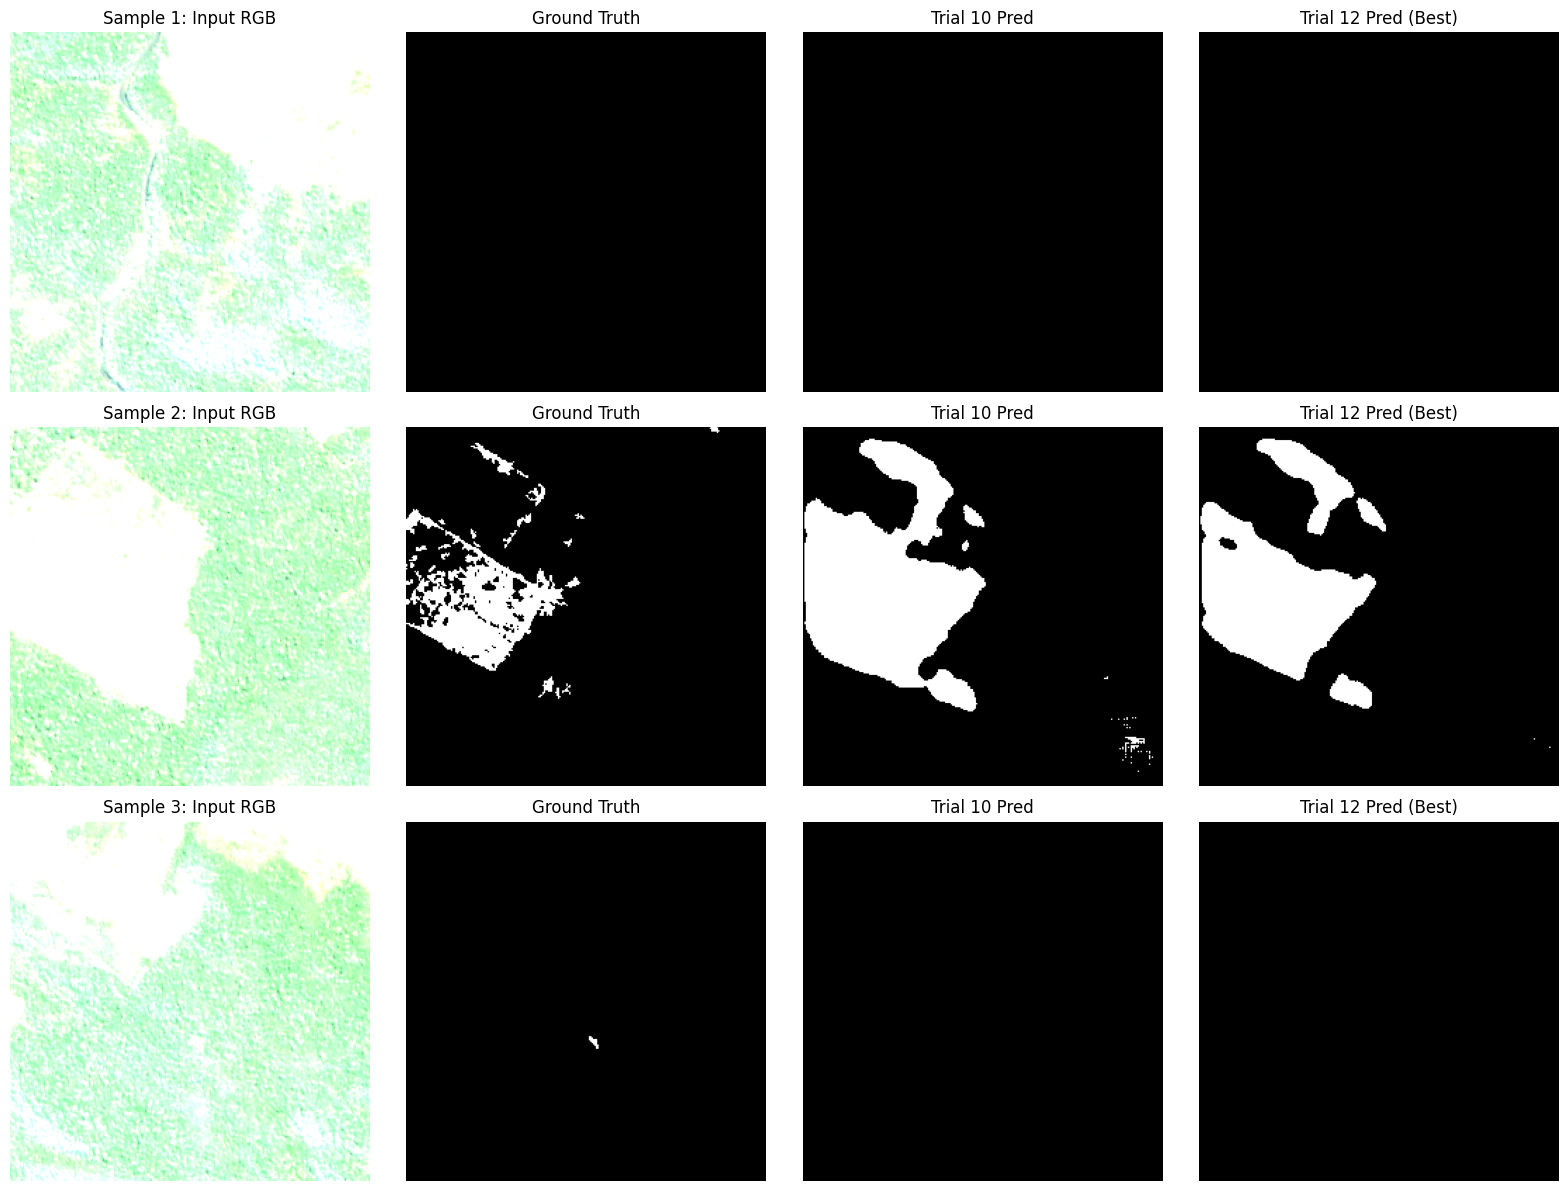

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import os
import torch
import segmentation_models_pytorch as smp

# 1. Load Trial 10 and Trial 12 models
model_10 = smp.Unet(encoder_name="resnet34", encoder_weights=None, in_channels=4, classes=1).to(device)
model_12 = smp.Unet(encoder_name="resnet34", encoder_weights=None, in_channels=4, classes=1).to(device)

model_10.load_state_dict(torch.load(os.path.join("models", "best_unet_trial_10.pth")))
model_12.load_state_dict(torch.load(os.path.join("models", "best_unet_trial_12.pth")))

model_10.eval()
model_12.eval()

# 2. Grab test samples
images_vis = X_te[:3].float().to(device)
masks_vis = y_te[:3].float().to(device)

with torch.no_grad():
    preds_10 = (torch.sigmoid(model_10(images_vis)) > 0.5).float()
    preds_12 = (torch.sigmoid(model_12(images_vis)) > 0.5).float()

images_cpu = images_vis.cpu().numpy()
masks_cpu = masks_vis.cpu().numpy()
p10_cpu = preds_10.cpu().numpy()
p12_cpu = preds_12.cpu().numpy()

# 3. Plot comparison
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for i in range(3):
    rgb_img = np.transpose(images_cpu[i, :3, :, :], (1, 2, 0))
    if rgb_img.max() > 1.0:
        rgb_img = rgb_img / 255.0
    rgb_img = np.clip(rgb_img, 0, 1)
    
    axes[i, 0].imshow(rgb_img)
    axes[i, 0].set_title(f"Sample {i+1}: Input RGB")
    axes[i, 0].axis('off')
    
    axes[i, 1].imshow(np.squeeze(masks_cpu[i]), cmap='gray')
    axes[i, 1].set_title("Ground Truth")
    axes[i, 1].axis('off')
    
    axes[i, 2].imshow(np.squeeze(p10_cpu[i]), cmap='gray')
    axes[i, 2].set_title("Trial 10 Pred")
    axes[i, 2].axis('off')
    
    axes[i, 3].imshow(np.squeeze(p12_cpu[i]), cmap='gray')
    axes[i, 3].set_title("Trial 12 Pred (Best)")
    axes[i, 3].axis('off')

plt.tight_layout()
plt.show()

In [20]:
import torch
import numpy as np
import os
import segmentation_models_pytorch as smp

# 1. Load the best model checkpoint (Trial 12)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_eval = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=4,
    classes=1
).to(device)

best_model_path = os.path.join("models", "best_unet_trial_12.pth")
model_eval.load_state_dict(torch.load(best_model_path))
model_eval.eval()

# 2. Initialize accumulators for global confusion metrics
total_intersection = 0.0
total_union = 0.0
total_tp = 0.0
total_fp = 0.0
total_fn = 0.0
total_tn = 0.0

threshold = 0.5

print("Evaluating model across the full test dataset...")

with torch.no_grad():
    for images, masks in test_loader:
        images, masks = images.to(device), masks.to(device)
        if masks.ndim == 3:
            masks = masks.unsqueeze(1)
            
        outputs = model_eval(images)
        preds = (torch.sigmoid(outputs) > threshold).float()
        
        # Intersection and Union for IoU
        intersection = (preds * masks).sum().item()
        union = preds.sum().item() + masks.sum().item() - intersection
        
        total_intersection += intersection
        total_union += union
        
        # Confusion matrix elements for Dice, Precision, Recall
        tp = (preds * masks).sum().item()
        fp = (preds * (1 - masks)).sum().item()
        fn = ((1 - preds) * masks).sum().item()
        tn = ((1 - preds) * (1 - masks)).sum().item()
        
        total_tp += tp
        total_fp += fp
        total_fn += fn
        total_tn += tn

# 3. Compute final aggregate metrics
mean_iou = (total_intersection + 1e-6) / (total_union + 1e-6)
dice_coeff = (2.0 * total_tp + 1e-6) / (2.0 * total_tp + total_fp + total_fn + 1e-6)
precision = (total_tp + 1e-6) / (total_tp + total_fp + 1e-6)
recall = (total_tp + 1e-6) / (total_tp + total_fn + 1e-6)
accuracy = (total_tp + total_tn + 1e-6) / (total_tp + total_tn + total_fp + total_fn + 1e-6)

print("\n" + "=" * 50)
print("FINAL TEST SET EVALUATION METRICS (Trial 12 Checkpoint)")
print("=" * 50)
print(f"Mean IoU          : {mean_iou:.4f}")
print(f"Dice Coefficient  : {dice_coeff:.4f}")
print(f"Precision         : {precision:.4f}")
print(f"Recall            : {recall:.4f}")
print(f"Pixel Accuracy    : {accuracy:.4f}")
print("=" * 50)

Evaluating model across the full test dataset...

FINAL TEST SET EVALUATION METRICS (Trial 12 Checkpoint)
Mean IoU          : 0.4143
Dice Coefficient  : 0.5859
Precision         : 0.4259
Recall            : 0.9381
Pixel Accuracy    : 0.9932


Visualizing the 3 most challenging test samples (lowest IoU)...


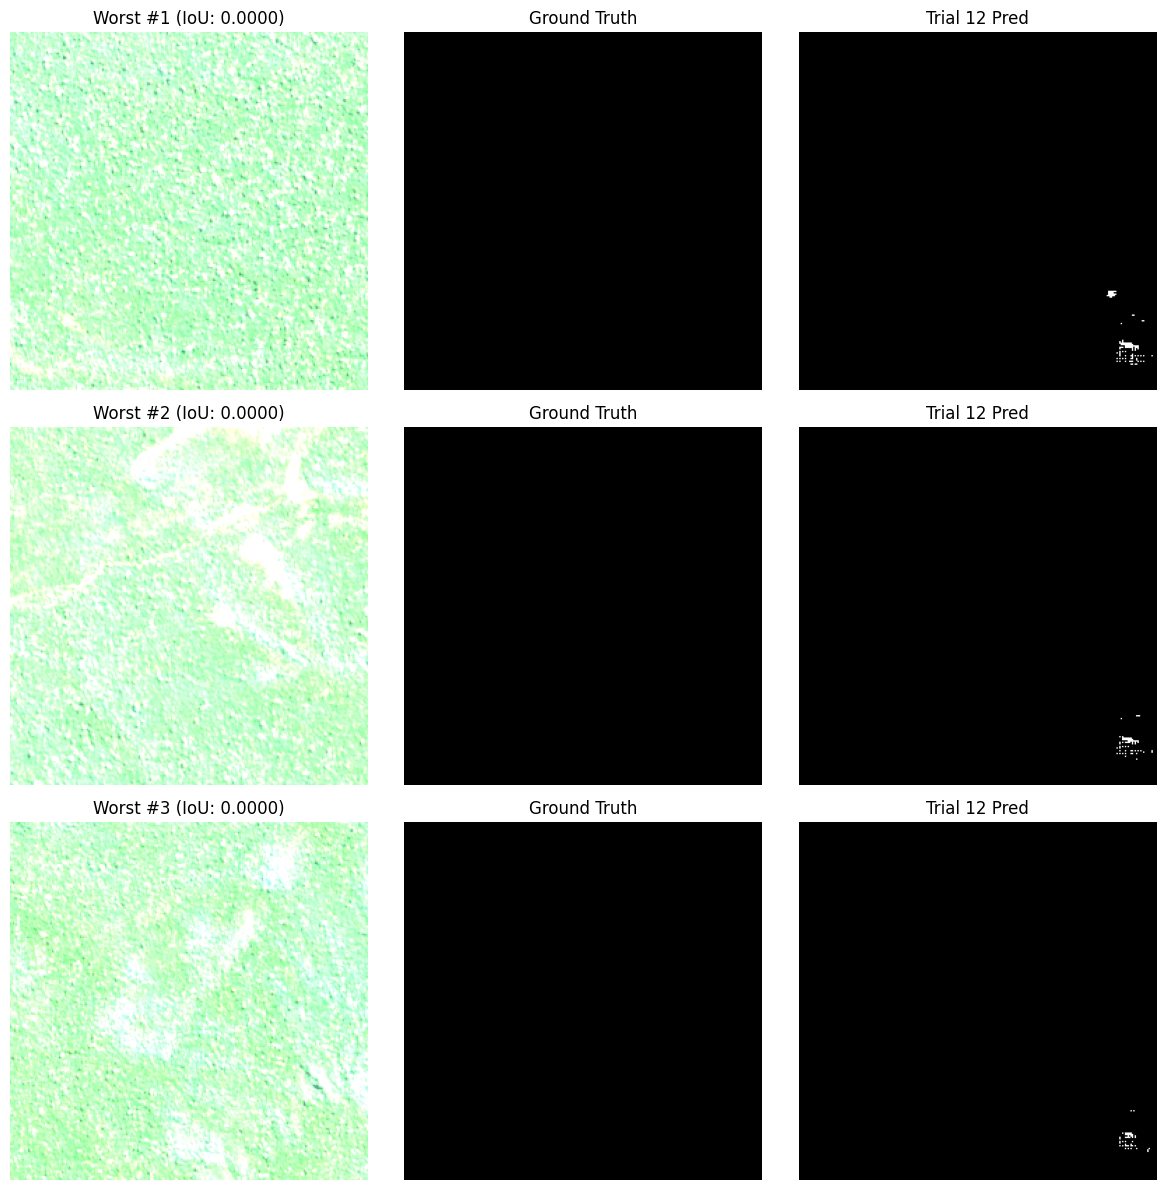


Running Threshold Sweep across Test Set...
---------------------------------------------
Threshold 0.30 | Mean IoU: 0.2122
Threshold 0.35 | Mean IoU: 0.2966
Threshold 0.40 | Mean IoU: 0.3568
Threshold 0.45 | Mean IoU: 0.3925
Threshold 0.50 | Mean IoU: 0.4143
Threshold 0.55 | Mean IoU: 0.4345
Threshold 0.60 | Mean IoU: 0.4556
---------------------------------------------
Optimal Threshold Found: 0.6 with Mean IoU: 0.4556


In [21]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import os
import segmentation_models_pytorch as smp

# 1. Load Trial 12 model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_eval = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=4,
    classes=1
).to(device)

model_eval.load_state_dict(torch.load(os.path.join("models", "best_unet_trial_12.pth")))
model_eval.eval()

# --- PART 1: ERROR ANALYSIS (WORST PREDICTIONS) ---
sample_ious = []
all_images = []
all_masks = []
all_preds = []

with torch.no_grad():
    for images, masks in test_loader:
        images, masks = images.to(device), masks.to(device)
        if masks.ndim == 3:
            masks = masks.unsqueeze(1)
            
        outputs = model_eval(images)
        preds = (torch.sigmoid(outputs) > 0.5).float()
        
        # Calculate individual IoU for each sample in the batch
        for i in range(images.size(0)):
            pred_i = preds[i]
            mask_i = masks[i]
            intersection = (pred_i * mask_i).sum().item()
            union = pred_i.sum().item() + mask_i.sum().item() - intersection
            iou = (intersection + 1e-6) / (union + 1e-6)
            
            sample_ious.append(iou)
            all_images.append(images[i].cpu())
            all_masks.append(masks[i].cpu())
            all_preds.append(preds[i].cpu())

sample_ious = np.array(sample_ious)
worst_indices = np.argsort(sample_ious)[:3] # Get the 3 lowest IoU samples

print("Visualizing the 3 most challenging test samples (lowest IoU)...")
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for idx, sample_idx in enumerate(worst_indices):
    rgb_img = np.transpose(all_images[sample_idx][:3].numpy(), (1, 2, 0))
    if rgb_img.max() > 1.0:
        rgb_img = rgb_img / 255.0
    rgb_img = np.clip(rgb_img, 0, 1)
    
    axes[idx, 0].imshow(rgb_img)
    axes[idx, 0].set_title(f"Worst #{idx+1} (IoU: {sample_ious[sample_idx]:.4f})")
    axes[idx, 0].axis('off')
    
    axes[idx, 1].imshow(all_masks[sample_idx].squeeze().numpy(), cmap='gray')
    axes[idx, 1].set_title("Ground Truth")
    axes[idx, 1].axis('off')
    
    axes[idx, 2].imshow(all_preds[sample_idx].squeeze().numpy(), cmap='gray')
    axes[idx, 2].set_title("Trial 12 Pred")
    axes[idx, 2].axis('off')

plt.tight_layout()
plt.show()

# --- PART 2: THRESHOLD SWEEP ---
thresholds = [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]
print("\nRunning Threshold Sweep across Test Set...")
print("-" * 45)

best_thresh = 0.5
best_sweep_iou = 0.0

for thresh in thresholds:
    total_intersection = 0.0
    total_union = 0.0
    
    with torch.no_grad():
        for images, masks in test_loader:
            images, masks = images.to(device), masks.to(device)
            if masks.ndim == 3:
                masks = masks.unsqueeze(1)
                
            outputs = model_eval(images)
            preds = (torch.sigmoid(outputs) > thresh).float()
            
            intersection = (preds * masks).sum().item()
            union = preds.sum().item() + masks.sum().item() - intersection
            
            total_intersection += intersection
            total_union += union
            
    sweep_iou = (total_intersection + 1e-6) / (total_union + 1e-6)
    print(f"Threshold {thresh:.2f} | Mean IoU: {sweep_iou:.4f}")
    
    if sweep_iou > best_sweep_iou:
        best_sweep_iou = sweep_iou
        best_thresh = thresh

print("-" * 45)
print(f"Optimal Threshold Found: {best_thresh} with Mean IoU: {best_sweep_iou:.4f}")